In [51]:
%pip install numpy pandas matplotlib

Note: you may need to restart the kernel to use updated packages.


In [52]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

print("Librerías cargadas correctamente.")

Librerías cargadas correctamente.


In [75]:
# ESCENARIO E: reconstrucción desde "Log Transformed Data"
# Los índices de fila comienzan en cero.

# Filas 29–50 de Excel = índices 29–50 de pandas:
# días 2–22; columnas 1–8 = t=0 y 10–17 = t=7 h.
bloque_log_E = datos_figura_1a.iloc[29:50, :18].copy()

datos_E = pd.DataFrame()
datos_E["dia"] = pd.to_numeric(
    bloque_log_E.iloc[:, 0], errors="coerce"
).to_numpy()

poblaciones_E = [f"S{i}" for i in range(1, 9)]

for i, poblacion in enumerate(poblaciones_E):
    # La sección transformada ya contiene log10(CFU/ml).
    datos_E[f"{poblacion}_t0"] = pd.to_numeric(
        bloque_log_E.iloc[:, 1 + i], errors="coerce"
    ).to_numpy()

    datos_E[f"{poblacion}_t7h"] = pd.to_numeric(
        bloque_log_E.iloc[:, 10 + i], errors="coerce"
    ).to_numpy()

    # Diferencia de log10 = log10 de la fracción superviviente.
    datos_E[f"{poblacion}_log10_supervivencia"] = (
        datos_E[f"{poblacion}_t7h"] - datos_E[f"{poblacion}_t0"]
    )

    datos_E[f"{poblacion}_supervivencia"] = (
        10.0 ** datos_E[f"{poblacion}_log10_supervivencia"]
    )

# Tabla larga para análisis por población y día.
observaciones_E = datos_E[
    ["dia"] + [f"{p}_supervivencia" for p in poblaciones_E]
].melt(
    id_vars="dia",
    var_name="poblacion",
    value_name="supervivencia"
)

observaciones_E["poblacion"] = observaciones_E["poblacion"].str.replace(
    "_supervivencia", "", regex=False
)

observaciones_E["log10_supervivencia"] = np.log10(
    observaciones_E["supervivencia"]
)

print("Dimensiones de datos_E:", datos_E.shape)
print("Días:", datos_E["dia"].min(), "a", datos_E["dia"].max())
print("Observaciones:", len(observaciones_E))

display(datos_E.head().round(6))

Dimensiones de datos_E: (21, 33)
Días: 2 a 22
Observaciones: 168


,dia,S1_t0,S1_t7h,S1_log10_supervivencia,S1_supervivencia,S2_t0,S2_t7h,S2_log10_supervivencia,S2_supervivencia,S3_t0,...,S6_log10_supervivencia,S6_supervivencia,S7_t0,S7_t7h,S7_log10_supervivencia,S7_supervivencia,S8_t0,S8_t7h,S8_log10_supervivencia,S8_supervivencia
0,2,7.544068,2.361728,-5.182340,0.000007,7.623249,2.690196,-4.933053,0.000012,7.806180,...,-5.564271,0.000003,7.612784,2.301030,-5.311754,0.000005,7.518514,2.230449,-5.288065,0.000005
1,3,7.531479,1.477121,-6.054358,0.000001,7.698970,1.845098,-5.853872,0.000001,7.612784,...,-3.924279,0.000119,7.491362,2.812913,-4.678448,0.000021,7.322219,3.146128,-4.176091,0.000067
2,4,7.447158,1.301030,-6.146128,0.000001,7.414973,1.698970,-5.716003,0.000002,7.414973,...,-2.617300,0.002414,7.397940,3.041393,-4.356547,0.000044,7.176091,3.397940,-3.778151,0.000167
3,5,7.505150,2.342423,-5.162727,0.000007,7.633468,2.477121,-5.156347,0.000007,7.255273,...,-2.339948,0.004571,7.643453,3.176091,-4.467361,0.000034,7.778151,4.176091,-3.602060,0.000250
4,6,7.397940,3.518514,-3.879426,0.000132,7.662758,3.079181,-4.583577,0.000026,7.491362,...,-2.541764,0.002872,7.612784,3.380211,-4.232573,0.000059,7.255273,4.908485,-2.346787,0.004500


In [81]:
print("Tipo:", type(datos_E))
print("Índice:", datos_E.index[:5].tolist())
print("Columnas duplicadas:", datos_E.columns[datos_E.columns.duplicated()].tolist())

print("\nValores actuales:")
print(datos_E[["dia", "S1_t0", "S1_t7h"]].iloc[:5].to_string(index=False))

print("\nValores de la primera fila por posición:")
print(datos_E.iloc[0, :5].to_dict())

Tipo: <class 'pandas.DataFrame'>
Índice: [0, 1, 2, 3, 4]
Columnas duplicadas: []

Valores actuales:
 dia    S1_t0   S1_t7h
   2 7.544068 2.361728
   3 7.531479 1.477121
   4 7.447158 1.301030
   5 7.505150 2.342423
   6 7.397940 3.518514

Valores de la primera fila por posición:
{'dia': 2.0, 'S1_t0': 7.544068044350276, 'S1_t7h': 2.361727836017593, 'S1_log10_supervivencia': -5.182340208332683, 'S1_supervivencia': 6.571428571428574e-06}


In [82]:
# Validación de los datos del Escenario E

columnas_supervivencia_E = [
    f"{p}_supervivencia" for p in poblaciones_E
]

print("Días:", datos_E["dia"].min(), "a", datos_E["dia"].max())
print("Número de días:", datos_E["dia"].nunique())
print("Valores ausentes:", datos_E.isna().sum().sum())

supervivencias_E = datos_E[columnas_supervivencia_E].to_numpy()

print("Supervivencias finitas:", np.isfinite(supervivencias_E).all())
print("Supervivencias >= 0:", (supervivencias_E >= 0).all())
print("Supervivencias <= 1:", (supervivencias_E <= 1).all())

print("\nResumen de supervivencia por población:")
display(datos_E[columnas_supervivencia_E].describe().T)

Días: 2 a 22
Número de días: 21
Valores ausentes: 0
Supervivencias finitas: True
Supervivencias >= 0: True
Supervivencias <= 1: True

Resumen de supervivencia por población:


,count,mean,std,min,25%,50%,75%,max
S1_supervivencia,21.0,0.235210,0.251135,7.142857e-07,0.000150,0.122857,0.500000,0.666667
S2_supervivencia,21.0,0.000022,0.000022,1.400000e-06,0.000009,0.000014,0.000026,0.000097
S3_supervivencia,21.0,0.097300,0.111298,1.538462e-06,0.000121,0.064706,0.188889,0.322222
S4_supervivencia,21.0,0.034981,0.059436,6.000000e-06,0.002071,0.012000,0.032308,0.215789
S5_supervivencia,21.0,0.182051,0.193177,1.333333e-06,0.013913,0.125000,0.276923,0.730769
S6_supervivencia,21.0,0.118136,0.131460,2.727273e-06,0.007273,0.075862,0.165625,0.433333
S7_supervivencia,21.0,0.058568,0.120284,4.878049e-06,0.000034,0.000091,0.007273,0.455556
S8_supervivencia,21.0,0.040540,0.068487,5.151515e-06,0.001813,0.008333,0.046667,0.233333


RESUMEN COMPARATIVO POR POBLACIÓN


,Media,Mediana,Desv. estándar,Mínimo,Máximo,Pendiente log10/día
S1,0.23521,0.12286,0.25113,0.00000,0.66667,0.31109
S2,0.00002,0.00001,0.00002,0.00000,0.00010,0.01681
S3,0.09730,0.06471,0.11130,0.00000,0.32222,0.26907
S4,0.03498,0.01200,0.05944,0.00001,0.21579,0.20680
S5,0.18205,0.12500,0.19318,0.00000,0.73077,0.20601
S6,0.11814,0.07586,0.13146,0.00000,0.43333,0.17092
S7,0.05857,0.00009,0.12028,0.00000,0.45556,0.23982
S8,0.04054,0.00833,0.06849,0.00001,0.23333,0.18170


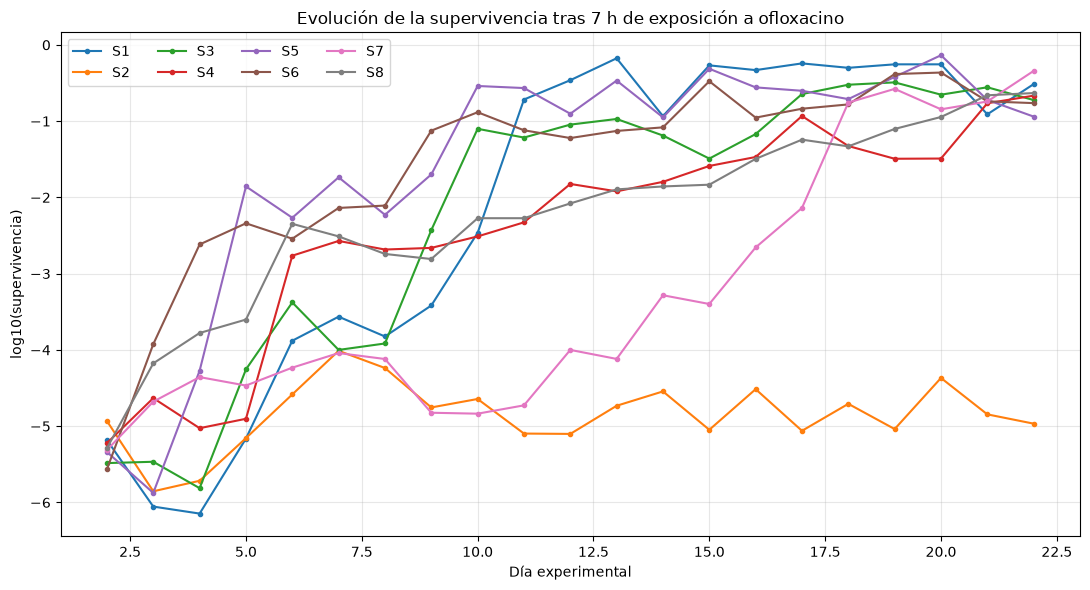

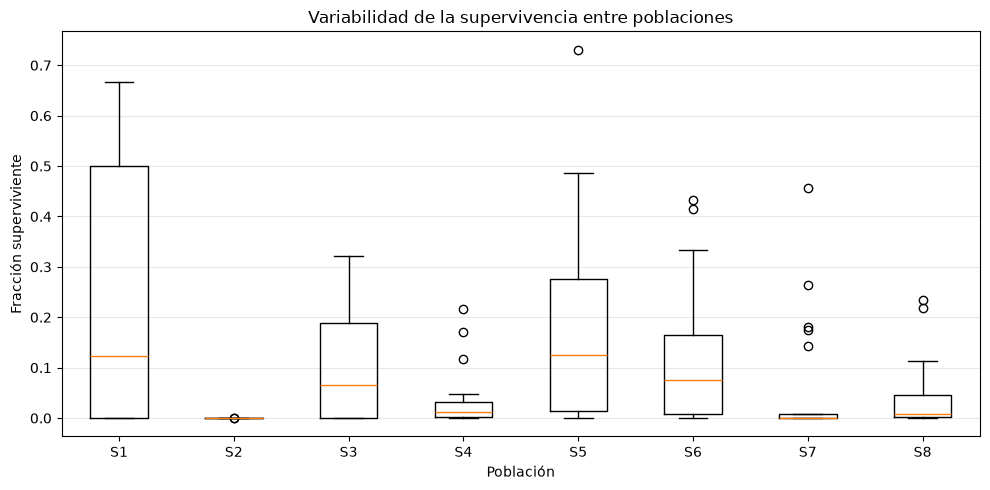

Mayor supervivencia media: S1
Menor supervivencia media: S2
Mayor pendiente log10/día: S1
Menor pendiente log10/día: S2


In [83]:
# ESCENARIO E — Análisis exploratorio completo de supervivencia

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

poblaciones_E = [f"S{i}" for i in range(1, 9)]
columnas_sup_E = [f"{p}_supervivencia" for p in poblaciones_E]

# 1. Resumen estadístico
resumen_E = datos_E[["dia"] + columnas_sup_E].copy()
estadisticas_E = resumen_E[columnas_sup_E].agg(
    ["mean", "median", "std", "min", "max"]
).T

estadisticas_E.index = poblaciones_E
estadisticas_E.columns = [
    "Media", "Mediana", "Desv. estándar", "Mínimo", "Máximo"
]

# Pendiente lineal de log10(supervivencia) por día.
# Es un resumen descriptivo, no una tasa de mutación.
pendientes_E = {}

for p in poblaciones_E:
    y = datos_E[f"{p}_log10_supervivencia"].to_numpy()
    x = datos_E["dia"].to_numpy()
    pendientes_E[p] = np.polyfit(x, y, 1)[0]

estadisticas_E["Pendiente log10/día"] = pd.Series(pendientes_E)

print("RESUMEN COMPARATIVO POR POBLACIÓN")
display(estadisticas_E.round(5))

# 2. Evolución temporal en escala logarítmica
plt.figure(figsize=(11, 6))

for p in poblaciones_E:
    plt.plot(
        datos_E["dia"],
        datos_E[f"{p}_log10_supervivencia"],
        marker="o",
        markersize=3,
        linewidth=1.5,
        label=p
    )

plt.xlabel("Día experimental")
plt.ylabel("log10(supervivencia)")
plt.title("Evolución de la supervivencia tras 7 h de exposición a ofloxacino")
plt.legend(ncol=4)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 3. Distribución comparativa de las supervivencias
plt.figure(figsize=(10, 5))

plt.boxplot(
    [datos_E[f"{p}_supervivencia"].to_numpy() for p in poblaciones_E],
    tick_labels=poblaciones_E
)

plt.xlabel("Población")
plt.ylabel("Fracción superviviente")
plt.title("Variabilidad de la supervivencia entre poblaciones")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# 4. Identificar los extremos por supervivencia media
medias_E = datos_E[columnas_sup_E].mean()
print("Mayor supervivencia media:", medias_E.idxmax().replace("_supervivencia", ""))
print("Menor supervivencia media:", medias_E.idxmin().replace("_supervivencia", ""))
print("Mayor pendiente log10/día:", max(pendientes_E, key=pendientes_E.get))
print("Menor pendiente log10/día:", min(pendientes_E, key=pendientes_E.get))

In [84]:
# Inspeccionar la interfaz del modelo y los parámetros del escenario E

import inspect
from src import euler_model

print("Funciones disponibles en euler_model:")
print([
    nombre for nombre, objeto in inspect.getmembers(euler_model, inspect.isfunction)
])

print("\nFirma de simular, si existe:")
if hasattr(euler_model, "simular"):
    print(inspect.signature(euler_model.simular))

print("\nFirma de load_params:")
print(inspect.signature(euler_model.load_params))

print("\nParámetros nominales del escenario E:")
print(euler_model.load_params("E"))

Funciones disponibles en euler_model:
['_num', 'concentracion', 'load_params', 'metricas', 'plot', 'rates', 'simulate', 'step']

Firma de simular, si existe:

Firma de load_params:
(scenario='B')

Parámetros nominales del escenario E:
({'rS': 1.0, 'rT': 0.9, 'rR': 0.8, 'dS': 2.0, 'dT': 0.5, 'dR': 0.1, 'muST': 0.0001, 'muTR': 1e-05, 'K': 100000000.0, 'x0': {'S': 10000000.0, 'T': 1000.0, 'R': 10.0}}, {'nota': 'Datos reales de evolución adaptativa con ofloxacino', 'fuente': 'Mohiuddin et al. (2025), Figura 1A', 'antibiotico': 'ofloxacino', 'concentracion_ug_ml': 5.0, 'dt_horas': 0.5, 'duracion_dias': 22, 'esquema': 'ciclico', 'C': 5.0, 'periodo_horas': 24.0, 'horas_exposicion': 7.0, 'horas_recuperacion': 17.0, 'tipo_datos': 'supervivencia_observada', 'poblaciones': ['S1', 'S2', 'S3', 'S4', 'S5', 'S6', 'S7', 'S8'], 'datos': 'data/literatura/Figure1a.xlsx', 'calibracion': 'pendiente'})


MÉTRICAS DEL MODELO NOMINAL
fraccion_R_final: 0.9986060867179101
t_dominancia_R_dias: 9.1875
t_extincion_S_dias: 6.291666666666666

¿Todas las trayectorias son finitas?: True
Mínimo de los estados simulados: 3.4200908521634774e-16


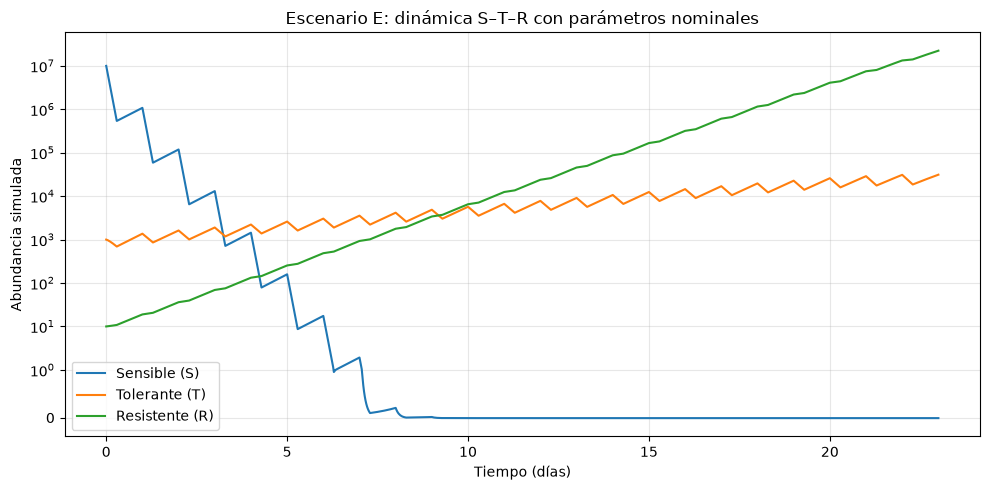


COMPARACIÓN DE SUPERVIVENCIA


,dia,supervivencia_modelo,S1_observada,S2_observada,S3_observada,S4_observada,S5_observada,S6_observada,S7_observada,S8_observada
0,2,0.062581,6.600000e-06,0.000012,0.000003,0.000006,0.000005,0.000003,0.000005,0.000005
1,3,0.130970,9.000000e-07,0.000001,0.000003,0.000023,0.000001,0.000119,0.000021,0.000067
2,4,0.422975,7.000000e-07,0.000002,0.000002,0.000009,0.000053,0.002414,0.000044,0.000167
3,5,0.631710,6.900000e-06,0.000007,0.000056,0.000013,0.013913,0.004571,0.000034,0.000250
4,6,0.683584,1.320000e-04,0.000026,0.000419,0.001720,0.005405,0.002872,0.000058,0.004500
5,7,0.718988,2.727000e-04,0.000097,0.000100,0.002684,0.018333,0.007273,0.000091,0.003080
6,8,0.762537,1.500000e-04,0.000058,0.000121,0.002071,0.005909,0.007812,0.000076,0.001813
7,9,0.815124,3.824000e-04,0.000018,0.003721,0.002177,0.020000,0.075000,0.000015,0.001556
8,10,0.872375,3.428600e-03,0.000023,0.079310,0.003077,0.288889,0.130769,0.000015,0.005333
9,11,0.927787,1.920000e-01,0.000008,0.060870,0.004706,0.271429,0.075862,0.000019,0.005333


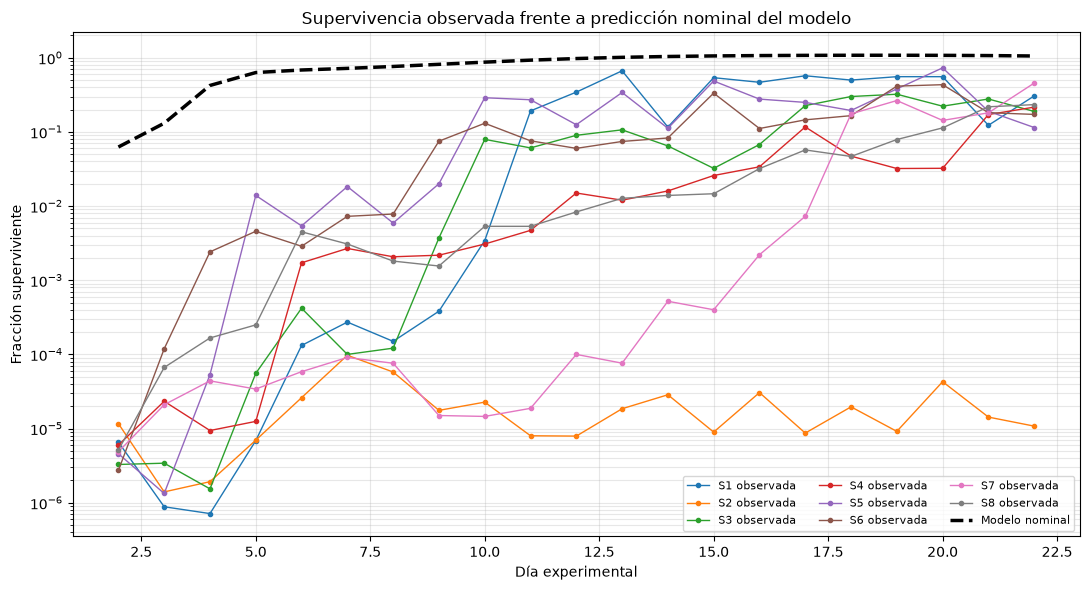


ERROR DESCRIPTIVO DEL MODELO NOMINAL


,poblacion,RMSE_log10_nominal
0,S1,2.7601
1,S2,4.7274
2,S3,2.6057
3,S4,2.5335
4,S5,1.9469
5,S6,1.7258
6,S7,3.4526
7,S8,2.2792


In [86]:
# ESCENARIO E: simulación nominal y comparación con datos experimentales

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src import euler_model

# Cargar parámetros nominales y configuración E
p_E, sc_E = euler_model.load_params("E")

# Copiar configuración para extender la simulación un día,
# de modo que podamos calcular la exposición del día 22 completa.
sc_comparacion_E = dict(sc_E)
sc_comparacion_E["duracion_dias"] = 23

# Simular sin modificar params.yaml ni los módulos compartidos
t_modelo_E, X_modelo_E, C_modelo_E, dt_E = (
    euler_model.simulate("E", p=p_E, sc=sc_comparacion_E)
)

# Métricas de la dinámica
metricas_E = euler_model.metricas(t_modelo_E, X_modelo_E)

print("MÉTRICAS DEL MODELO NOMINAL")
for nombre, valor in metricas_E.items():
    print(f"{nombre}: {valor}")

# Comprobar que las trayectorias son válidas
print("\n¿Todas las trayectorias son finitas?:",
      np.isfinite(X_modelo_E).all())
print("Mínimo de los estados simulados:", X_modelo_E.min())

# Graficar abundancias absolutas
plt.figure(figsize=(10, 5))
for i, nombre in enumerate(["Sensible (S)", "Tolerante (T)", "Resistente (R)"]):
    plt.plot(t_modelo_E, X_modelo_E[:, i], label=nombre)

plt.xlabel("Tiempo (días)")
plt.ylabel("Abundancia simulada")
plt.title("Escenario E: dinámica S–T–R con parámetros nominales")
plt.yscale("symlog", linthresh=1)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Calcular supervivencia total predicha durante 7 horas de exposición.
# dt = 0.5 h, por tanto 7 h corresponden a 14 pasos.
pasos_7h_E = int(round((7.0 / 24.0) / dt_E))
N_modelo_E = X_modelo_E.sum(axis=1)

dias_comparacion_E = np.arange(2, 23)
supervivencia_modelo_E = []

for dia in dias_comparacion_E:
    i_inicio = int(round(dia / dt_E))
    i_fin = i_inicio + pasos_7h_E

    N_inicio = N_modelo_E[i_inicio]
    N_fin = N_modelo_E[i_fin]

    if N_inicio > 0:
        supervivencia_modelo_E.append(N_fin / N_inicio)
    else:
        supervivencia_modelo_E.append(np.nan)

supervivencia_modelo_E = np.asarray(supervivencia_modelo_E)

# Tabla de comparación: una predicción nominal frente a ocho poblaciones.
tabla_comparacion_E = pd.DataFrame({
    "dia": dias_comparacion_E,
    "supervivencia_modelo": supervivencia_modelo_E
})

for poblacion in [f"S{i}" for i in range(1, 9)]:
    tabla_comparacion_E[f"{poblacion}_observada"] = (
        datos_E.set_index("dia")
        .loc[dias_comparacion_E, f"{poblacion}_supervivencia"]
        .to_numpy()
    )

print("\nCOMPARACIÓN DE SUPERVIVENCIA")
display(tabla_comparacion_E.head(10).round(7))

# Gráfica en escala logarítmica: datos observados y predicción nominal
plt.figure(figsize=(11, 6))

for poblacion in [f"S{i}" for i in range(1, 9)]:
    plt.plot(
        dias_comparacion_E,
        tabla_comparacion_E[f"{poblacion}_observada"],
        marker=".",
        linewidth=1,
        label=f"{poblacion} observada"
    )

plt.plot(
    dias_comparacion_E,
    supervivencia_modelo_E,
    color="black",
    linestyle="--",
    linewidth=2.5,
    label="Modelo nominal"
)

plt.xlabel("Día experimental")
plt.ylabel("Fracción superviviente")
plt.title("Supervivencia observada frente a predicción nominal del modelo")
plt.yscale("log")
plt.legend(ncol=3, fontsize=8)
plt.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.show()

# RMSE descriptivo en log10, comparando la misma predicción
# con cada población. No equivale a calibrar parámetros.
epsilon_E = 1e-12
log_pred_E = np.log10(np.maximum(supervivencia_modelo_E, epsilon_E))

resultados_rmse_E = []

for poblacion in [f"S{i}" for i in range(1, 9)]:
    observado = tabla_comparacion_E[f"{poblacion}_observada"].to_numpy()
    log_obs = np.log10(np.maximum(observado, epsilon_E))

    rmse = np.sqrt(np.mean((log_obs - log_pred_E) ** 2))

    resultados_rmse_E.append({
        "poblacion": poblacion,
        "RMSE_log10_nominal": rmse
    })

print("\nERROR DESCRIPTIVO DEL MODELO NOMINAL")
display(pd.DataFrame(resultados_rmse_E).round(4))

In [87]:
print("Días originales:")
print(datos_E["dia"].head(5).tolist())

print("\nDías de comparación:")
print(dias_comparacion_E[:5].tolist())

print("\nPrimeras filas de la tabla:")
print(tabla_comparacion_E[
    ["dia", "supervivencia_modelo", "S1_observada", "S2_observada"]
].head(5).to_string(index=False))

Días originales:
[2, 3, 4, 5, 6]

Días de comparación:
[2, 3, 4, 5, 6]

Primeras filas de la tabla:
 dia  supervivencia_modelo  S1_observada  S2_observada
   2              0.062581  6.571429e-06      0.000012
   3              0.130970  8.823529e-07      0.000001
   4              0.422975  7.142857e-07      0.000002
   5              0.631710  6.875000e-06      0.000007
   6              0.683584  1.320000e-04      0.000026
